# Taller N.º 1 - Aprendizaje Supervisado
## Equipo 7 - Sistemas de recomendacion: filtrado colaborativo y personalizacion
### Implementacion W1: Factorizacion de matrices supervisada

**Dataset:** MovieLens `ml-32m` (32.000.204 ratings, 87.585 peliculas, 200.948 usuarios, 1995-2023).

EDA sobre el dataset completo; modelado sobre una submuestra reproducible por usuarios. Semillas fijas para reproducibilidad.

## 0. Configuracion y reproducibilidad

- Semilla unica y rutas del dataset (detecta local / Colab).
- `ratings.csv` ocupa ~1 GB en RAM: el EDA usa los 32M completos; el modelado, una submuestra por usuarios (`N_USERS_SAMPLE`) para entrenar en minutos.

In [1]:
# === Librerías estándar del taller ===
import os
import gc
import time
import random
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# === Reproducibilidad: una única semilla para todo el cuaderno ===
SEED = 42
random.seed(SEED)
np.random.seed(SEED)

# === Estética de gráficos ===
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (9, 5)
plt.rcParams["axes.titlesize"] = 13
plt.rcParams["figure.dpi"] = 110

print("pandas :", pd.__version__)
print("numpy  :", np.__version__)
print("Semilla global fijada en SEED =", SEED)

pandas : 3.1.0
numpy  : 2.5.4
Semilla global fijada en SEED = 42


In [3]:
# === Resolución automática de la ruta del dataset (local Windows o Colab) ===
CANDIDATE_PATHS = [
    Path(r"C:\Users\andre\OneDrive\Documentos\TranajosML\Workshop1\dataSet"),  # tu equipo
    Path("dataSet"),                                                            # ruta relativa
]

DATA_DIR = next((p for p in CANDIDATE_PATHS if (p / "ratings.csv").exists()), None)
if DATA_DIR is None:
    raise FileNotFoundError(
        "No se encontró 'ratings.csv'. Edita CANDIDATE_PATHS con la ruta correcta de tu dataSet."
    )

RATINGS_CSV = DATA_DIR / "ratings.csv"
MOVIES_CSV  = DATA_DIR / "movies.csv"
TAGS_CSV    = DATA_DIR / "tags.csv"
LINKS_CSV   = DATA_DIR / "links.csv"

print("Dataset en:", DATA_DIR)
for f in [RATINGS_CSV, MOVIES_CSV, TAGS_CSV, LINKS_CSV]:
    print(f"  {f.name:12s} -> {f.stat().st_size/1e6:8.1f} MB")

Dataset en: C:\Users\andre\OneDrive\Documentos\TranajosML\Workshop1\dataSet
  ratings.csv  ->    877.1 MB
  movies.csv   ->      4.2 MB
  tags.csv     ->     72.4 MB
  links.csv    ->      2.0 MB


In [4]:
# === Hiperparámetros de escala y de preparación de datos ===

# Tamaño de la submuestra para MODELADO (nº de usuarios muestreados al azar).
N_USERS_SAMPLE       = 15_000   # factorización (holgado en 16 GB)
N_USERS_SAMPLE_TREES = 6_000    # baselines con árboles/GBM

# Filtros de densidad (combaten el cold-start y el ruido de la cola larga).
MIN_RATINGS_PER_USER = 10  
MIN_RATINGS_PER_ITEM = 10   

# Umbral para la variante de CLASIFICACIÓN (like / no-like).
LIKE_THRESHOLD = 4.0        

# Ranking top-N: K por defecto para Precision@K, Recall@K, NDCG@K, MAP@K, HitRate@K.
TOP_K = 10

# Particiones temporales (fracciones del eje de tiempo).
TEST_FRACTION = 0.10        # 10% más reciente -> test
VAL_FRACTION  = 0.10        # 10% siguiente     -> validación

# Se compactan los tipos de datos pa' que no explote la ram
RATINGS_DTYPES = {
    "userId":    "int32",
    "movieId":   "int32",
    "rating":    "float32",
    "timestamp": "int64",
}

print("Configuración de escala lista.")
print(f"  N_USERS_SAMPLE       = {N_USERS_SAMPLE:,}")
print(f"  MIN_RATINGS_PER_USER = {MIN_RATINGS_PER_USER}")
print(f"  MIN_RATINGS_PER_ITEM = {MIN_RATINGS_PER_ITEM}")
print(f"  LIKE_THRESHOLD       = {LIKE_THRESHOLD}")

Configuración de escala lista.
  N_USERS_SAMPLE       = 15,000
  MIN_RATINGS_PER_USER = 10
  MIN_RATINGS_PER_ITEM = 10
  LIKE_THRESHOLD       = 4.0


## 1. Planteamiento del problema

Recomendacion como aprendizaje supervisado: la etiqueta es el `rating` observado.

| Formulacion | Objetivo | Tarea | Metricas |
|---|---|---|---|
| Prediccion de rating | `rating` 0.5-5.0 | Regresion | RMSE, MAE |
| Like / no-like | `like = 1 si rating >= 4.0` | Ranking top-N | P@K, R@K, NDCG@K, MAP@K, HitRate@K |

**Por que factorizacion de matrices:** la matriz usuario-item (200.948 x 87.585) esta >99,8% vacia. MF comprime esa matriz en `k` factores latentes y predice `r_hat_ui = mu + b_u + b_i + p_u . q_i`, generalizando a pares no observados. Es el estandar de referencia en recomendacion.

## 2. Carga y exploracion (EDA)

Dimensiones, nulos/duplicados, distribucion de ratings, cola larga, sparsity, generos, anos y deriva temporal. El EDA usa los 32M completos.

### 2.1 Carga

`ratings.csv` se lee con dtypes compactos (`int32`/`float32`) para reducir memoria.

In [5]:
t0 = time.time()

ratings = pd.read_csv(RATINGS_CSV, dtype=RATINGS_DTYPES)
movies  = pd.read_csv(MOVIES_CSV,  dtype={"movieId": "int32"})
links   = pd.read_csv(LINKS_CSV)
tags    = pd.read_csv(TAGS_CSV, dtype={"userId": "int32", "movieId": "int32"})

print("ratings:", ratings.shape)
print("movies :", movies.shape)
print("tags   :", tags.shape)
print("links  :", links.shape)
print("\nMemoria ratings: {:.0f} MB".format(ratings.memory_usage(deep=True).sum()/1e6))
display(ratings.head())

ratings: (32000204, 4)
movies : (87585, 3)
tags   : (2000072, 4)
links  : (87585, 3)

Memoria ratings: 640 MB


,userId,movieId,rating,timestamp
0,1,17,4.0,944249077
1,1,25,1.0,944250228
2,1,29,2.0,943230976
3,1,30,5.0,944249077
4,1,32,5.0,943228858


In [6]:
# Convertimos timestamp (segundos UTC desde 1970) a datetime: 
# se usará en el análisis temporal y en la partición cronológica train/val/test.
ratings["datetime"] = pd.to_datetime(ratings["timestamp"], unit="s")
ratings["year"]  = ratings["datetime"].dt.year.astype("int16")
ratings["month"] = ratings["datetime"].dt.month.astype("int8")

print("Rango temporal de los ratings:")
print("  desde:", ratings["datetime"].min())
print("  hasta:", ratings["datetime"].max())

Rango temporal de los ratings:
  desde: 1995-01-09 11:46:44
  hasta: 2023-10-13 02:29:07


### 2.2 Dimensiones, tipos, nulos y duplicados

In [7]:
print("=== ratings.info() ===")
ratings.info(show_counts=True)

print("\n=== Nulos por columna ===")
print(ratings.isnull().sum())

# Un (userId, movieId) debería ser único: cada usuario valora una película una vez.
dup = ratings.duplicated(subset=["userId", "movieId"]).sum()
print(f"\nPares (userId, movieId) duplicados: {dup:,}")


n_users  = ratings["userId"].nunique()
n_items  = ratings["movieId"].nunique()
n_obs    = len(ratings)
print(f"\nUsuarios únicos : {n_users:,}")
print(f"Películas únicas: {n_items:,}")
print(f"Ratings totales : {n_obs:,}")

=== ratings.info() ===
<class 'pandas.DataFrame'>
RangeIndex: 32000204 entries, 0 to 32000203
Data columns (total 7 columns):
 #   Column     Non-Null Count     Dtype         
---  ------     --------------     -----         
 0   userId     32000204 non-null  int32         
 1   movieId    32000204 non-null  int32         
 2   rating     32000204 non-null  float32       
 3   timestamp  32000204 non-null  int64         
 4   datetime   32000204 non-null  datetime64[us]
 5   year       32000204 non-null  int16         
 6   month      32000204 non-null  int8          
dtypes: datetime64[us](1), float32(1), int16(1), int32(2), int64(1), int8(1)
memory usage: 946.1 MB

=== Nulos por columna ===
userId       0
movieId      0
rating       0
timestamp    0
datetime     0
year         0
month        0
dtype: int64

Pares (userId, movieId) duplicados: 0

Usuarios únicos : 200,948
Películas únicas: 84,432
Ratings totales : 32,000,204


### 2.3 Distribucion de ratings

Reparto en la escala 0.5-5.0; marca el sesgo de positividad y el umbral de like.

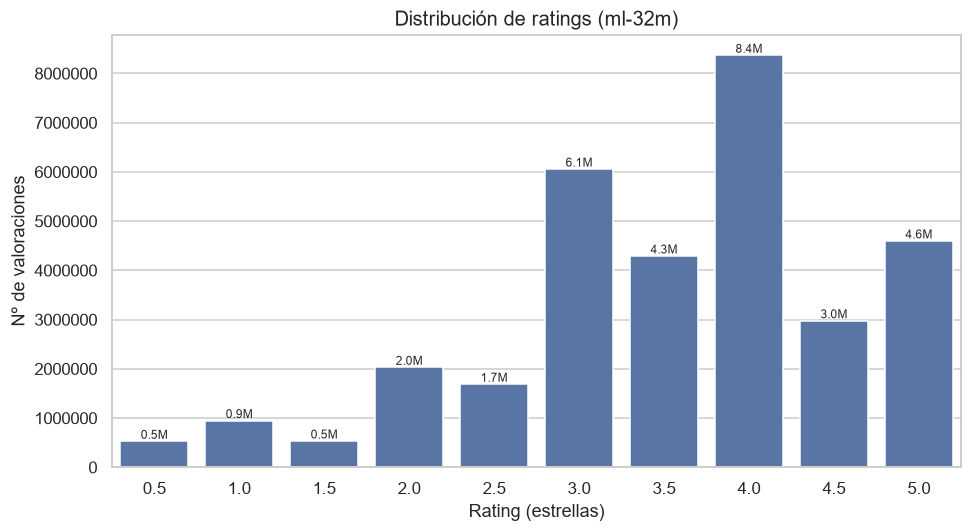

Media global de rating: 3.5404
Mediana: 3.5
% de ratings >= 4.0 (like): 49.8%


In [8]:
rating_counts = ratings["rating"].value_counts().sort_index()

fig, ax = plt.subplots()
sns.barplot(x=rating_counts.index.astype(str), y=rating_counts.values,
            color="#4C72B0", ax=ax)
ax.set_title("Distribución de ratings (ml-32m)")
ax.set_xlabel("Rating (estrellas)")
ax.set_ylabel("Nº de valoraciones")
ax.ticklabel_format(style="plain", axis="y")
for i, v in enumerate(rating_counts.values):
    ax.text(i, v, f"{v/1e6:.1f}M", ha="center", va="bottom", fontsize=8)
plt.tight_layout(); plt.show()

print("Media global de rating:", round(ratings['rating'].mean(), 4))
print("Mediana:", ratings['rating'].median())
pct_like = (ratings['rating'] >= LIKE_THRESHOLD).mean()*100
print(f"% de ratings >= {LIKE_THRESHOLD} (like): {pct_like:.1f}%")

La distribución está sesgada hacia valores altos: los ratings de 3.0, 4.0 y 5.0 dominan, y hay muchas menos valoraciones muy bajas. Esto indica un *sesgo de positividad*: los usuarios valoran sobre todo películas que eligieron ver. Las medias estrellas (0.5, 1.5, …) son menos frecuentes que las enteras. Este sesgo justifica incluir un término de **media global μ** en el modelo y explica por qué un umbral de *like* en 4.0 deja una fracción relevante de positivos.

### 2.4 Actividad por usuario y popularidad por pelicula (cola larga)

Esperamos ley de potencias: pocos usuarios/peliculas acumulan casi todas las interacciones.

In [9]:
ratings_per_user = ratings.groupby("userId").size()
ratings_per_item = ratings.groupby("movieId").size()

print("Ratings por USUARIO:")
display(ratings_per_user.describe(percentiles=[.25, .5, .75, .9, .99]))
print("\nRatings por PELÍCULA:")
display(ratings_per_item.describe(percentiles=[.25, .5, .75, .9, .99]))

Ratings por USUARIO:


count    200948.000000
mean        159.246193
std         282.025462
min          20.000000
25%          36.000000
50%          73.000000
75%         167.000000
90%         364.000000
99%        1290.000000
max       33332.000000
dtype: float64


Ratings por PELÍCULA:


count     84432.000000
mean        379.005638
std        2592.439791
min           1.000000
25%           2.000000
50%           5.000000
75%          25.000000
90%         248.900000
99%        9263.140000
max      102929.000000
dtype: float64

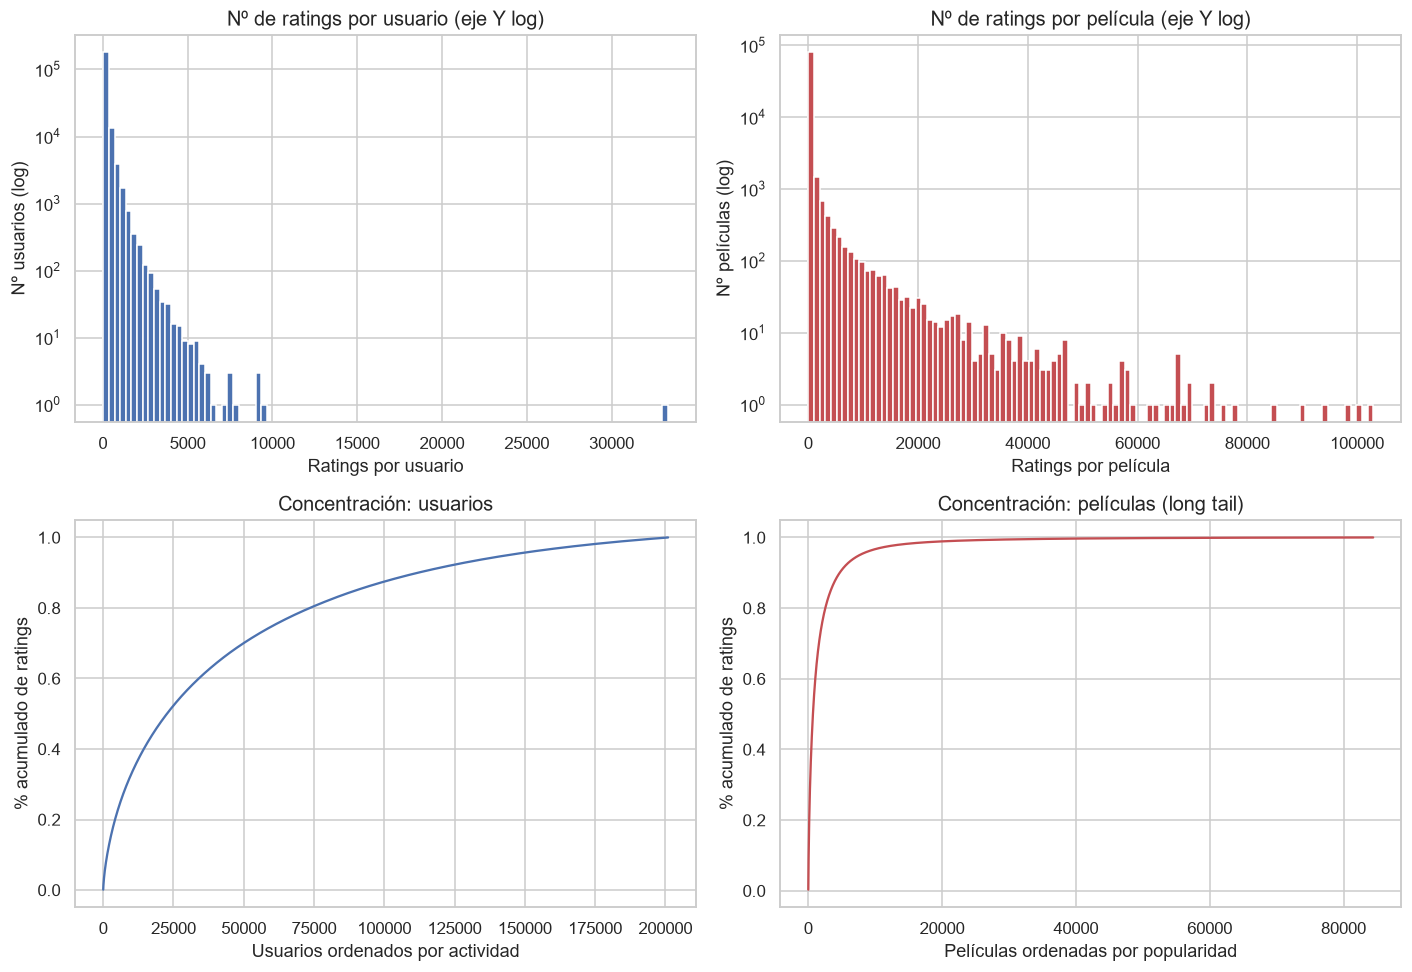

El 1% de películas más populares concentra el 54.8% de todos los ratings.


In [10]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9))

# Histogramas en escala log-Y.
axes[0, 0].hist(ratings_per_user, bins=100, color="#4C72B0")
axes[0, 0].set_yscale("log")
axes[0, 0].set_title("Nº de ratings por usuario (eje Y log)")
axes[0, 0].set_xlabel("Ratings por usuario"); axes[0, 0].set_ylabel("Nº usuarios (log)")

axes[0, 1].hist(ratings_per_item, bins=100, color="#C44E52")
axes[0, 1].set_yscale("log")
axes[0, 1].set_title("Nº de ratings por película (eje Y log)")
axes[0, 1].set_xlabel("Ratings por película"); axes[0, 1].set_ylabel("Nº películas (log)")

# Curvas de concentración: % acumulado de ratings vs. % de ítems/usuarios ordenados.
item_sorted = np.sort(ratings_per_item.values)[::-1]
user_sorted = np.sort(ratings_per_user.values)[::-1]
axes[1, 0].plot(np.cumsum(user_sorted)/user_sorted.sum(), color="#4C72B0")
axes[1, 0].set_title("Concentración: usuarios")
axes[1, 0].set_xlabel("Usuarios ordenados por actividad")
axes[1, 0].set_ylabel("% acumulado de ratings")
axes[1, 1].plot(np.cumsum(item_sorted)/item_sorted.sum(), color="#C44E52")
axes[1, 1].set_title("Concentración: películas (long tail)")
axes[1, 1].set_xlabel("Películas ordenadas por popularidad")
axes[1, 1].set_ylabel("% acumulado de ratings")

plt.tight_layout(); plt.show()

# Cuantificamos la concentración (regla tipo Pareto).
top1pct_items = int(0.01 * len(item_sorted))
share = item_sorted[:top1pct_items].sum() / item_sorted.sum() * 100
print(f"El 1% de películas más populares concentra el {share:.1f}% de todos los ratings.")

Ambas distribuciones son fuertemente asimétricas (escala log en Y). Un puñado de usuarios muy activos y de *blockbusters* acumula la mayor parte de las interacciones, mientras una larga cola de títulos apenas tiene ratings. Las curvas de concentración muestran lo empinado que es el reparto.

Consecuencia práctica: los ítems de la cola sufrirán **cold-start** y predicciones poco fiables, lo que justifica (a) un término de **sesgo de ítem**, (b) el filtrado por soporte mínimo, y (c) medir cobertura y novedad en la evaluación.

### 2.5 Sparsity de la matriz usuario-item

In [11]:
total_cells = n_users * n_items
density  = n_obs / total_cells
sparsity = 1 - density

print(f"Usuarios × Películas = {n_users:,} × {n_items:,} = {total_cells:,} celdas")
print(f"Ratings observados   = {n_obs:,}")
print(f"Densidad  = {density*100:.4f}%")
print(f"Sparsity  = {sparsity*100:.4f}%")

Usuarios × Películas = 200,948 × 84,432 = 16,966,441,536 celdas
Ratings observados   = 32,000,204
Densidad  = 0.1886%
Sparsity  = 99.8114%


La matriz es dispersa en más del 99,8 %: casi todas las combinaciones usuario-película nunca ocurren. Rellenar esos huecos con heurísticas no funciona; se necesita un modelo que infiera preferencias a partir de patrones compartidos. Esto es exactamente el caso de uso de la **factorización de matrices**.

### 2.6 Géneros

Catálogo por género y rating medio por género (sobre una muestra de ratings).

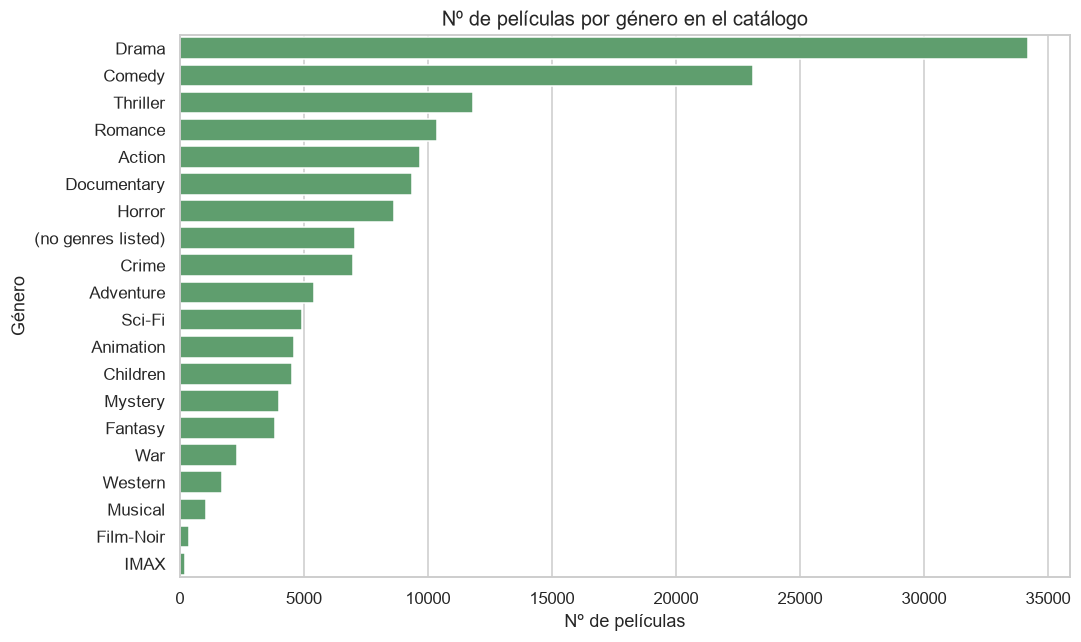

genres_list
Drama                 34175
Comedy                23124
Thriller              11823
Romance               10369
Action                 9668
Documentary            9363
Horror                 8654
(no genres listed)     7080
Crime                  6976
Adventure              5402
Name: count, dtype: int64

In [12]:
# Extraemos el año del título: 'Toy Story (1995)' -> 1995 usando Regex
movies["year_movie"] = movies["title"].str.extract(r"\((\d{4})\)").astype("float")
movies["genres_list"] = movies["genres"].str.split("|")


genres_exploded = movies.explode("genres_list")
genre_catalog_counts = genres_exploded["genres_list"].value_counts()

fig, ax = plt.subplots(figsize=(10, 6))
sns.barplot(y=genre_catalog_counts.index, x=genre_catalog_counts.values,
            color="#55A868", ax=ax)
ax.set_title("Nº de películas por género en el catálogo")
ax.set_xlabel("Nº de películas"); ax.set_ylabel("Género")
plt.tight_layout(); plt.show()

display(genre_catalog_counts.head(10))

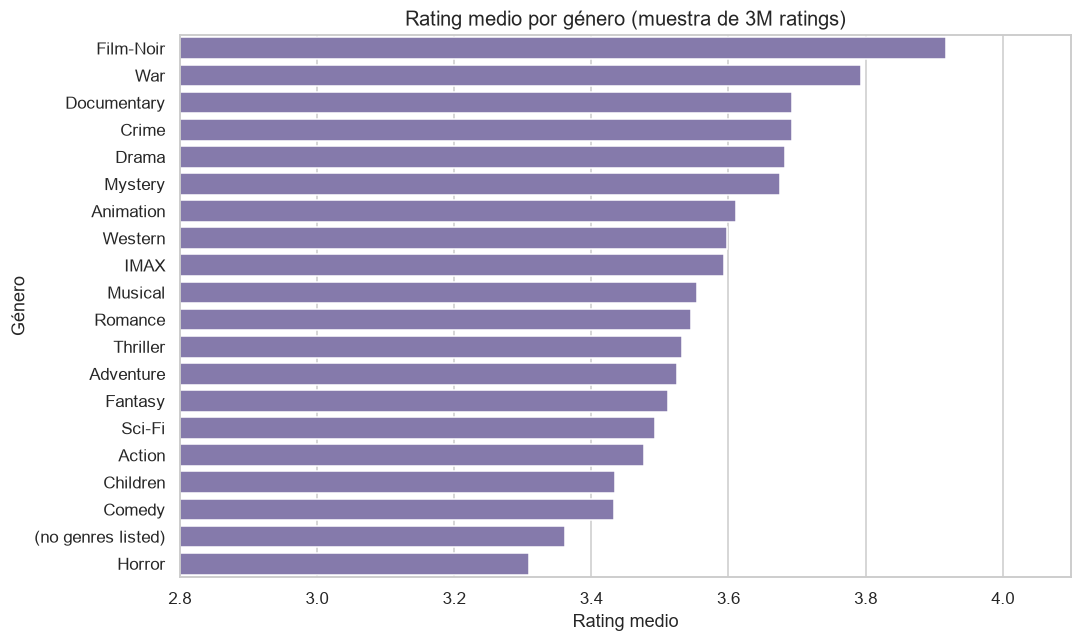

,mean,count
genres_list,,
Film-Noir,3.917,28332
War,3.794,149022
Documentary,3.693,40194
Crime,3.692,504455
Drama,3.682,1309995
Mystery,3.675,245349
Animation,3.611,207222
Western,3.598,55938
IMAX,3.594,140085


In [13]:
# Rating medio por género: unimos una MUESTRA de ratings con los géneros.
sample_for_genre = ratings.sample(n=min(3_000_000, len(ratings)), random_state=SEED)
merged = sample_for_genre.merge(movies[["movieId", "genres_list"]], on="movieId", how="left")
genre_ratings = merged.explode("genres_list")

genre_mean = (genre_ratings.groupby("genres_list")["rating"]
              .agg(["mean", "count"]).sort_values("mean", ascending=False))
genre_mean = genre_mean[genre_mean["count"] > 1000]  # evitar géneros marginales

fig, ax = plt.subplots(figsize=(10, 6))
sns.barplot(y=genre_mean.index, x=genre_mean["mean"], color="#8172B3", ax=ax)
ax.set_xlim(2.8, 4.1)
ax.set_title("Rating medio por género (muestra de 3M ratings)")
ax.set_xlabel("Rating medio"); ax.set_ylabel("Género")
plt.tight_layout(); plt.show()

display(genre_mean.round(3))

El catálogo está dominado por *Drama* y *Comedy* (los géneros más numerosos). En cuanto a valoración media, géneros como *Film-Noir*, *War* o *Documentary* suelen puntuar algo más alto —obras más 'de nicho' que ve quien ya las busca— mientras géneros masivos como *Horror* o *Comedy* quedan por debajo. La diferencia entre géneros es moderada (banda ~3.0–3.9), señal de que el género por sí solo explica poco: hará falta la señal latente por usuario.

### 2.7 Años y evolución temporal

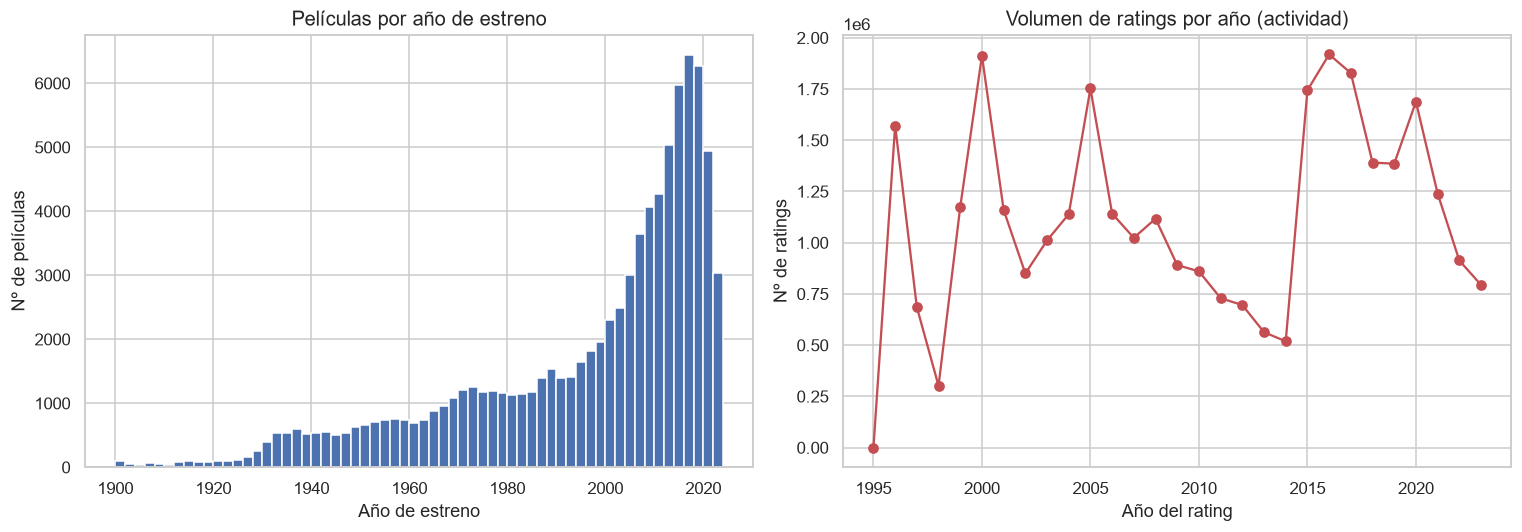

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# (a) Nº de películas por año de estreno.
year_counts = movies["year_movie"].dropna().astype(int)
year_counts = year_counts[(year_counts >= 1900) & (year_counts <= 2023)]
axes[0].hist(year_counts, bins=range(1900, 2025, 2), color="#4C72B0")
axes[0].set_title("Películas por año de estreno")
axes[0].set_xlabel("Año de estreno"); axes[0].set_ylabel("Nº de películas")

# (b) Volumen de ratings por año en que se emitieron.
ratings_by_year = ratings.groupby("year").size()
axes[1].plot(ratings_by_year.index, ratings_by_year.values, marker="o", color="#C44E52")
axes[1].set_title("Volumen de ratings por año (actividad)")
axes[1].set_xlabel("Año del rating"); axes[1].set_ylabel("Nº de ratings")

plt.tight_layout(); plt.show()

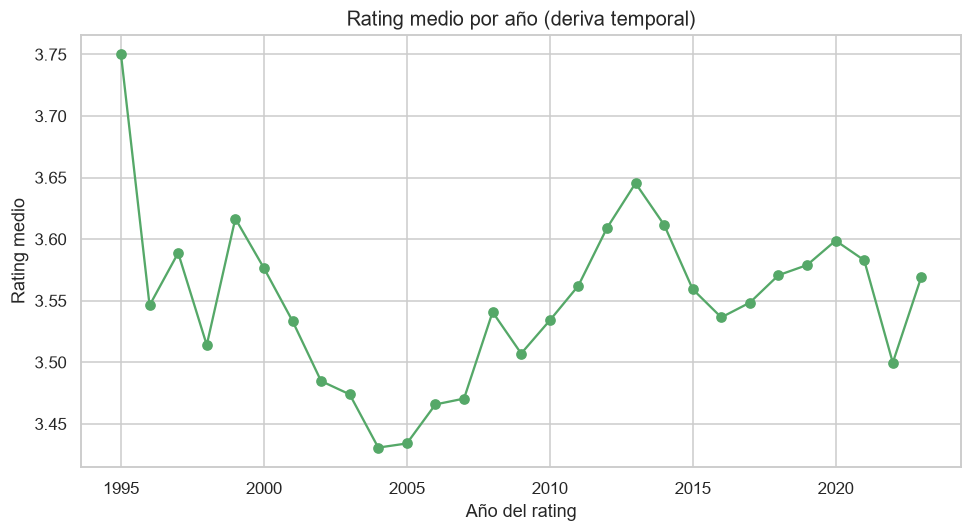

year
1995    3.750
1996    3.546
1997    3.589
1998    3.514
1999    3.617
2000    3.576
2001    3.534
2002    3.485
2003    3.474
2004    3.431
2005    3.434
2006    3.466
2007    3.470
2008    3.541
2009    3.507
2010    3.534
2011    3.562
2012    3.609
2013    3.645
2014    3.612
2015    3.559
2016    3.536
2017    3.548
2018    3.571
2019    3.579
2020    3.599
2021    3.583
2022    3.500
2023    3.570
Name: rating, dtype: float32

In [ ]:
# ¿Cambia el rating medio a lo largo del tiempo? 
mean_by_year = ratings.groupby("year")["rating"].mean()

fig, ax = plt.subplots()
ax.plot(mean_by_year.index, mean_by_year.values, marker="o", color="#55A868")
ax.set_title("Rating medio por año (deriva temporal)")
ax.set_xlabel("Año del rating"); ax.set_ylabel("Rating medio")
plt.tight_layout(); plt.show()



El catálogo crece con fuerza a partir de los años 90 y especialmente en las últimas dos décadas. La actividad de ratings tiene picos y el rating medio **no es constante** entre años: hay una deriva temporal suave. Esto tiene una consecuencia metodológica directa: una **partición temporal** (entrenar con el pasado, validar/evaluar con el futuro) refleja mejor el uso real del sistema y evita el optimismo de mezclar épocas.

Los ratings están sesgados al alza (media ~3.5), la actividad sigue una cola larga en usuarios y películas, y la matriz es >99,8 % dispersa. Drama/Comedy dominan el catálogo y existe deriva temporal del rating medio. Todo ello justifica usar factorización con sesgos, filtrar por soporte mínimo y particionar temporalmente.

## 3. Preparacion de los datos

Submuestra por usuarios -> filtro de soporte minimo -> IDs contiguos -> variable `like` -> particion temporal train/val/test (sin leakage).

### 3.1 Submuestreo por usuarios

Muestreamos usuarios completos (no ratings sueltos) para no partir perfiles.

In [16]:
all_users = ratings["userId"].unique()
rng = np.random.default_rng(SEED)

if N_USERS_SAMPLE < len(all_users):
    sampled_users = rng.choice(all_users, size=N_USERS_SAMPLE, replace=False)
    df = ratings[ratings["userId"].isin(sampled_users)].copy()
    print(f"Submuestra: {N_USERS_SAMPLE:,} usuarios de {len(all_users):,}.")
else:
    df = ratings.copy()
    print("N_USERS_SAMPLE >= nº de usuarios: se usa el dataset completo.")

print(f"Ratings en la submuestra: {len(df):,}")

Submuestra: 15,000 usuarios de 200,948.
Ratings en la submuestra: 2,435,256


### 3.2 Filtrado de soporte minimo

Descartamos usuarios/items con pocas interacciones: con poco soporte los factores latentes no se estiman bien. Iterativo porque un filtro afecta al otro.

In [17]:
def filter_min_support(data, min_u, min_i, max_iter=10):
    """Filtra iterativamente usuarios/ítems con poco soporte hasta estabilizar."""
    prev = None
    for it in range(max_iter):
        uc = data["userId"].value_counts()
        data = data[data["userId"].isin(uc[uc >= min_u].index)]
        ic = data["movieId"].value_counts()
        data = data[data["movieId"].isin(ic[ic >= min_i].index)]
        if prev == len(data):
            break
        prev = len(data)
    return data.copy()

before = len(df)
df = filter_min_support(df, MIN_RATINGS_PER_USER, MIN_RATINGS_PER_ITEM)
print(f"Ratings: {before:,} -> {len(df):,} (eliminados {before-len(df):,})")
print(f"Usuarios: {df['userId'].nunique():,}  |  Películas: {df['movieId'].nunique():,}")

Ratings: 2,435,256 -> 2,368,980 (eliminados 66,276)
Usuarios: 14,998  |  Películas: 11,589


### 3.3 IDs contiguos

Reindexamos a 0..n-1 para indexar P y Q sin huecos. Guardamos los mapeos para traducir a titulos luego.

In [18]:
user_ids = df["userId"].unique()
item_ids = df["movieId"].unique()

user2idx = {uid: i for i, uid in enumerate(user_ids)}
item2idx = {iid: i for i, iid in enumerate(item_ids)}
idx2item = {i: iid for iid, i in item2idx.items()}  # para recomendar títulos luego

df["u"] = df["userId"].map(user2idx).astype("int32")
df["i"] = df["movieId"].map(item2idx).astype("int32")

N_U = len(user2idx)
N_I = len(item2idx)
print(f"Índices contiguos -> usuarios: 0..{N_U-1}  |  ítems: 0..{N_I-1}")
display(df[["userId", "u", "movieId", "i", "rating"]].head())

Índices contiguos -> usuarios: 0..14997  |  ítems: 0..11588


,userId,u,movieId,i,rating
0,1,0,17,0,4.0
1,1,0,25,1,1.0
2,1,0,29,2,2.0
3,1,0,30,3,5.0
4,1,0,32,4,5.0


### 3.4 Variable `like`

`like = 1` si `rating >= LIKE_THRESHOLD`. La regresion sigue usando `rating`.

In [19]:
df["like"] = (df["rating"] >= LIKE_THRESHOLD).astype("int8")
print(f"Proporción de 'like' (rating >= {LIKE_THRESHOLD}): {df['like'].mean()*100:.1f}%")
print(df['like'].value_counts())

Proporción de 'like' (rating >= 4.0): 50.2%
like
1    1188664
0    1180316
Name: count, dtype: int64


### 3.5 Particion temporal train/val/test

Se usa el corte **temporal** (no aleatorio): train = pasado, val = intermedio, test = 10% mas reciente. Imita el despliegue real (predecir el futuro con el pasado) y evita el optimismo de mezclar epocas.

Sin leakage: el corte es por tiempo global y todas las features/parametros se estiman solo con train.

In [20]:
def temporal_split(data, test_frac, val_frac):
    """Corte cronológico global: train (pasado) / val / test (futuro reciente)."""
    data = data.sort_values("timestamp", kind="mergesort").reset_index(drop=True)
    n = len(data)
    n_test = int(n * test_frac)
    n_val  = int(n * val_frac)
    n_train = n - n_val - n_test
    train = data.iloc[:n_train]
    val   = data.iloc[n_train:n_train + n_val]
    test  = data.iloc[n_train + n_val:]
    return train.copy(), val.copy(), test.copy()

train_df, val_df, test_df = temporal_split(df, TEST_FRACTION, VAL_FRACTION)

print(f"train: {len(train_df):,}  ({train_df['datetime'].min().date()} -> {train_df['datetime'].max().date()})")
print(f"val  : {len(val_df):,}  ({val_df['datetime'].min().date()} -> {val_df['datetime'].max().date()})")
print(f"test : {len(test_df):,}  ({test_df['datetime'].min().date()} -> {test_df['datetime'].max().date()})")

train: 1,895,184  (1996-01-29 -> 2018-08-18)
val  : 236,898  (2018-08-18 -> 2020-09-15)
test : 236,898  (2020-09-15 -> 2023-10-13)


#### Cold-start de la particion

Un corte temporal puede dejar usuarios/items en val/test no vistos en train. Los contamos y los retiramos para una evaluacion limpia.

In [21]:
train_users = set(train_df["u"].unique())
train_items = set(train_df["i"].unique())

def report_and_clean(name, part):
    mask_known = part["u"].isin(train_users) & part["i"].isin(train_items)
    cold = (~mask_known).sum()
    print(f"{name}: {cold:,} filas con usuario/ítem no visto en train "
          f"({cold/len(part)*100:.2f}%) -> se retiran para evaluación limpia")
    return part[mask_known].copy()

val_df  = report_and_clean("val ", val_df)
test_df = report_and_clean("test", test_df)

print(f"\nTamaños finales -> train: {len(train_df):,} | val: {len(val_df):,} | test: {len(test_df):,}")

val : 203,806 filas con usuario/ítem no visto en train (86.03%) -> se retiran para evaluación limpia
test: 213,347 filas con usuario/ítem no visto en train (90.06%) -> se retiran para evaluación limpia

Tamaños finales -> train: 1,895,184 | val: 33,092 | test: 23,551


In [22]:
# Liberamos memoria del DataFrame completo de 32M si ya no lo necesitamos
del ratings
gc.collect()
print("Memoria del dataset completo liberada. Datos de modelado listos en train_df/val_df/test_df.")

Memoria del dataset completo liberada. Datos de modelado listos en train_df/val_df/test_df.


## 4. Ingenieria de caracteristicas

Features de usuario/item (media, conteo), sesgos `mu`/`b_u`/`b_i`, generos one-hot, año y antiguedad. Todo se calcula solo con train para evitar leakage.

In [23]:
# Estadísticos por usuario/ítem estimados SOLO en train.
mu = train_df["rating"].mean()  # media global

user_stats = train_df.groupby("u")["rating"].agg(u_mean="mean", u_count="size")
item_stats = train_df.groupby("i")["rating"].agg(i_mean="mean", i_count="size")

# Sesgos tipo baseline: b_u y b_i como desviaciones respecto a mu.
user_bias = (user_stats["u_mean"] - mu).rename("b_u")
item_bias = (item_stats["i_mean"] - mu).rename("b_i")

print(f"mu = {mu:.4f}")
display(user_stats.describe().round(3))
display(item_stats.describe().round(3))

mu = 3.5401


,u_mean,u_count
count,12695.000,12695.000
mean,3.675,149.286
std,0.469,234.763
min,0.875,1.000
25%,3.409,35.000
50%,3.698,70.000
75%,3.981,160.000
max,5.000,3779.000


,i_mean,i_count
count,10796.000,10796.000
mean,3.301,175.545
std,0.539,423.314
min,0.812,1.000
25%,3.000,15.000
50%,3.375,38.000
75%,3.696,133.000
max,5.000,6401.000


In [24]:
# Generos one-hot + ano por pelicula (indexado por 'i'). movies sigue en memoria.
movies_idx = movies[movies["movieId"].isin(item2idx)].copy()
movies_idx["i"] = movies_idx["movieId"].map(item2idx)

genre_ohe = (movies_idx.assign(g=movies_idx["genres"].str.split("|"))
             .explode("g")
             .pivot_table(index="i", columns="g", aggfunc="size", fill_value=0))
genre_ohe = (genre_ohe > 0).astype("int8")
genre_ohe.columns = [f"g_{c}" for c in genre_ohe.columns]

item_year = movies_idx.set_index("i")["year_movie"].rename("item_year")
print("Generos one-hot:", genre_ohe.shape, "| columnas:", list(genre_ohe.columns)[:5], "...")

Generos one-hot: (11589, 20) | columnas: ['g_(no genres listed)', 'g_Action', 'g_Adventure', 'g_Animation', 'g_Children'] ...


In [25]:
def build_feature_matrix(part):
    """Ensambla la tabla de features (user/item/sesgos/genero/ano/temporal).
    Todas las estadisticas provienen de train -> sin leakage."""
    X = part[["u", "i", "year", "rating", "like"]].copy()
    X = X.join(user_stats, on="u").join(item_stats, on="i")
    X = X.join(user_bias, on="u").join(item_bias, on="i")
    X = X.join(item_year, on="i").join(genre_ohe, on="i")
    # Feature temporal: antiguedad de la pelicula al momento del rating.
    X["movie_age"] = (X["year"] - X["item_year"]).clip(lower=0)
    X = X.fillna({"u_mean": mu, "i_mean": mu, "b_u": 0.0, "b_i": 0.0,
                  "u_count": 0, "i_count": 0, "item_year": X["item_year"].median(),
                  "movie_age": 0})
    return X.fillna(0)

X_train = build_feature_matrix(train_df)
X_val   = build_feature_matrix(val_df)
X_test  = build_feature_matrix(test_df)

FEATURE_COLS = [c for c in X_train.columns if c not in ("rating", "like", "u", "i")]
print(f"No de features: {len(FEATURE_COLS)}")
print(FEATURE_COLS)

No de features: 29
['year', 'u_mean', 'u_count', 'i_mean', 'i_count', 'b_u', 'b_i', 'item_year', 'g_(no genres listed)', 'g_Action', 'g_Adventure', 'g_Animation', 'g_Children', 'g_Comedy', 'g_Crime', 'g_Documentary', 'g_Drama', 'g_Fantasy', 'g_Film-Noir', 'g_Horror', 'g_IMAX', 'g_Musical', 'g_Mystery', 'g_Romance', 'g_Sci-Fi', 'g_Thriller', 'g_War', 'g_Western', 'movie_age']


## 5. Baselines

Popularity, Bias (`mu+b_u+b_i`), kNN item-item (coseno sparse) y modelos tabulares (Ridge, Lasso, DecisionTree, RandomForest, GradientBoosting). Aqui se definen tambien las metricas RMSE/MAE y de ranking.

In [26]:
from sklearn.metrics import mean_squared_error, mean_absolute_error

def rmse(y, yhat): return float(np.sqrt(mean_squared_error(y, yhat)))
def mae(y, yhat):  return float(mean_absolute_error(y, yhat))

# Clipping a la escala valida [0.5, 5.0].
def clip_rating(x): return np.clip(x, 0.5, 5.0)

results = {}  # acumulador de metricas de rating
def log_result(name, y, yhat):
    r, m = rmse(y, clip_rating(yhat)), mae(y, clip_rating(yhat))
    results[name] = {"RMSE": r, "MAE": m}
    print(f"{name:22s}  RMSE={r:.4f}  MAE={m:.4f}")
    return r, m

In [27]:
# --- Metricas de ranking top-N (sobre 'like') ---
def dcg_at_k(rels):
    rels = np.asarray(rels, dtype=float)
    return np.sum(rels / np.log2(np.arange(2, rels.size + 2)))

def ranking_metrics(recommended, relevant, k):
    rec_k = recommended[:k]
    hits = [1 if it in relevant else 0 for it in rec_k]
    n_rel = len(relevant)
    if n_rel == 0:
        return None
    precision = sum(hits) / k
    recall    = sum(hits) / n_rel
    hit_rate  = 1.0 if sum(hits) > 0 else 0.0
    idcg = dcg_at_k(sorted(hits, reverse=True)) or 1.0
    ndcg = dcg_at_k(hits) / idcg
    ap, acc = 0.0, 0
    for rank, h in enumerate(hits, start=1):
        if h:
            acc += 1
            ap += acc / rank
    ap = ap / min(n_rel, k)
    return dict(precision=precision, recall=recall, ndcg=ndcg, map=ap, hit=hit_rate)

def evaluate_ranking(score_fn, k=TOP_K, max_users=2000, n_neg=200):
    """score_fn(u, items)->scores. Relevantes = items con like==1 en test."""
    rng_local = np.random.default_rng(SEED)
    test_pos = test_df[test_df["like"] == 1].groupby("u")["i"].apply(set)
    users = test_pos.index.to_numpy()
    if len(users) > max_users:
        users = rng_local.choice(users, max_users, replace=False)
    seen = train_df.groupby("u")["i"].apply(set)
    all_items = np.arange(N_I)
    agg = {kk: [] for kk in ["precision", "recall", "ndcg", "map", "hit"]}
    for u in users:
        relevant = test_pos[u]
        seen_u = seen.get(u, set())
        negs = rng_local.choice(all_items, size=min(n_neg, N_I), replace=False)
        cand = np.array(list(relevant | (set(negs) - seen_u)))
        scores = score_fn(u, cand)
        order = cand[np.argsort(-scores)]
        m = ranking_metrics(list(order), relevant, k)
        if m:
            for kk in agg: agg[kk].append(m[kk])
    return {f"P@{k}": np.mean(agg["precision"]), f"R@{k}": np.mean(agg["recall"]),
            f"NDCG@{k}": np.mean(agg["ndcg"]), f"MAP@{k}": np.mean(agg["map"]),
            f"HitRate@{k}": np.mean(agg["hit"])}

ranking_results = {}

### 5.1 Popularity y Bias

Popularity recomienda por nº de ratings; Bias predice `mu+b_u+b_i` (referencia a batir).

In [28]:
bu = user_bias.to_dict(); bi = item_bias.to_dict()
def bias_predict(df_part):
    return (mu
            + df_part["u"].map(bu).fillna(0).to_numpy()
            + df_part["i"].map(bi).fillna(0).to_numpy())

log_result("GlobalMean",     test_df["rating"], np.full(len(test_df), mu))
log_result("Bias(mu+bu+bi)", test_df["rating"], bias_predict(test_df))

GlobalMean              RMSE=1.0212  MAE=0.7686
Bias(mu+bu+bi)          RMSE=0.8966  MAE=0.6680


(0.8965672750716976, 0.6680115313900691)

In [29]:
item_pop = train_df.groupby("i").size()
pop_vec = np.zeros(N_I); pop_vec[item_pop.index.to_numpy()] = item_pop.to_numpy()
bi_vec = np.zeros(N_I)
for i_, v in bi.items(): bi_vec[i_] = v
bu_arr = np.zeros(N_U)
for u_, v in bu.items(): bu_arr[u_] = v

ranking_results["Popularity"] = evaluate_ranking(lambda u, items: pop_vec[items])
ranking_results["Bias"]       = evaluate_ranking(lambda u, items: mu + bu_arr[u] + bi_vec[items])
for name in ["Popularity", "Bias"]:
    print(name, {k: round(v, 4) for k, v in ranking_results[name].items()})

Popularity {'P@10': np.float64(0.393), 'R@10': np.float64(0.2728), 'NDCG@10': np.float64(0.6726), 'MAP@10': np.float64(0.3624), 'HitRate@10': np.float64(0.8471)}
Bias {'P@10': np.float64(0.2786), 'R@10': np.float64(0.1983), 'NDCG@10': np.float64(0.5209), 'MAP@10': np.float64(0.1911), 'HitRate@10': np.float64(0.7951)}


### 5.2 kNN item-item

Coseno entre items sobre la matriz centrada; prediccion por media ponderada de vecinos.

In [30]:
from scipy.sparse import csr_matrix
from sklearn.metrics.pairwise import cosine_similarity

r_centered = train_df["rating"].to_numpy() - train_df["i"].map(item_stats["i_mean"]).to_numpy()
R = csr_matrix((r_centered, (train_df["u"], train_df["i"])), shape=(N_U, N_I))

KNN_K = 40
item_sim = cosine_similarity(R.T, dense_output=False)

def knn_predict_rating(df_part):
    Rt = R.tocsr()
    preds = np.empty(len(df_part))
    i_mean = item_stats["i_mean"].to_dict()
    for row, (u_, i_) in enumerate(zip(df_part["u"].to_numpy(), df_part["i"].to_numpy())):
        sims = item_sim.getrow(i_).toarray().ravel()
        user_items = Rt.getrow(u_).indices
        if user_items.size == 0:
            preds[row] = i_mean.get(i_, mu); continue
        s = sims[user_items]
        top = np.argsort(-s)[:KNN_K]
        idx = user_items[top]; w = sims[idx]
        denom = np.abs(w).sum()
        if denom == 0:
            preds[row] = i_mean.get(i_, mu); continue
        preds[row] = i_mean.get(i_, mu) + (w * Rt[u_, idx].toarray().ravel()).sum() / denom
    return preds

knn_eval = test_df.sample(n=min(20_000, len(test_df)), random_state=SEED)
log_result("kNN item-item", knn_eval["rating"], knn_predict_rating(knn_eval))

kNN item-item           RMSE=0.8287  MAE=0.6144


(0.8286734546252191, 0.6143755420476198)

### 5.3 Modelos tabulares

Ridge/Lasso y arboles sobre las features de la seccion 4 (submuestra de filas para acotar coste).

In [31]:
from sklearn.linear_model import Ridge, Lasso
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor

Xtr, ytr = X_train[FEATURE_COLS].to_numpy(), X_train["rating"].to_numpy()
Xte, yte = X_test[FEATURE_COLS].to_numpy(),  X_test["rating"].to_numpy()

n_tree_rows = min(len(Xtr), N_USERS_SAMPLE_TREES * 150)
ridx = np.random.default_rng(SEED).choice(len(Xtr), n_tree_rows, replace=False)
Xtr_s, ytr_s = Xtr[ridx], ytr[ridx]

models = {
    "Ridge":            Ridge(alpha=1.0, random_state=SEED),
    "Lasso":            Lasso(alpha=0.001, random_state=SEED, max_iter=5000),
    "DecisionTree":     DecisionTreeRegressor(max_depth=12, random_state=SEED),
    "RandomForest":     RandomForestRegressor(n_estimators=80, max_depth=16,
                                              n_jobs=-1, random_state=SEED),
    "GradientBoosting": GradientBoostingRegressor(n_estimators=150, max_depth=3,
                                                  random_state=SEED),
}

for name, mdl in models.items():
    t = time.time()
    use_sub = name in ("DecisionTree", "RandomForest", "GradientBoosting")
    mdl.fit(Xtr_s if use_sub else Xtr, ytr_s if use_sub else ytr)
    log_result(name, yte, mdl.predict(Xte))
    print(f"   ({time.time()-t:.1f}s)")

Ridge                   RMSE=0.8730  MAE=0.6552
   (0.6s)
Lasso                   RMSE=0.8727  MAE=0.6550
   (27.6s)
DecisionTree            RMSE=0.9061  MAE=0.6741
   (10.2s)
RandomForest            RMSE=0.8778  MAE=0.6529
   (223.4s)
GradientBoosting        RMSE=0.8868  MAE=0.6614
   (646.4s)


## 6. Factorizacion de matrices (FunkSVD con SGD)

`r_hat_ui = mu + b_u + b_i + p_u . q_i`. Perdida L2 regularizada, optimizada por SGD. Implementacion propia con numpy.

Actualizaciones por observacion (error `e = r - r_hat`):
- `b_u += lr*(e - lam*b_u)`, `b_i += lr*(e - lam*b_i)`
- `p_u += lr*(e*q_i - lam*p_u)`, `q_i += lr*(e*p_u - lam*q_i)`

In [32]:
class FunkSVD:
    """Factorizacion de matrices con sesgos, entrenada por SGD."""
    def __init__(self, n_users, n_items, k=50, lr=0.01, reg=0.05,
                 n_epochs=20, seed=SEED):
        self.k, self.lr, self.reg, self.n_epochs = k, lr, reg, n_epochs
        rng = np.random.default_rng(seed)
        self.P = rng.normal(0, 0.1, (n_users, k))
        self.Q = rng.normal(0, 0.1, (n_items, k))
        self.bu = np.zeros(n_users)
        self.bi = np.zeros(n_items)
        self.mu = 0.0
        self.history_ = []

    def fit(self, u, i, r, val=None, verbose=True):
        self.mu = r.mean()
        n = len(r)
        rng = np.random.default_rng(SEED)
        for ep in range(self.n_epochs):
            order = rng.permutation(n)
            for idx in order:
                uu, ii, rr = u[idx], i[idx], r[idx]
                pred = self.mu + self.bu[uu] + self.bi[ii] + self.P[uu] @ self.Q[ii]
                e = rr - pred
                self.bu[uu] += self.lr * (e - self.reg * self.bu[uu])
                self.bi[ii] += self.lr * (e - self.reg * self.bi[ii])
                pu = self.P[uu].copy()
                self.P[uu] += self.lr * (e * self.Q[ii] - self.reg * self.P[uu])
                self.Q[ii] += self.lr * (e * pu - self.reg * self.Q[ii])
            if val is not None:
                vr = rmse(val[2], self.predict(val[0], val[1]))
                self.history_.append(vr)
                if verbose: print(f"  epoca {ep+1:2d}/{self.n_epochs}  val RMSE={vr:.4f}")
        return self

    def predict(self, u, i):
        return (self.mu + self.bu[u] + self.bi[i]
                + np.sum(self.P[u] * self.Q[i], axis=1))

    def predict_items(self, u, items):
        return self.mu + self.bu[u] + self.bi[items] + self.Q[items] @ self.P[u]

In [33]:
u_tr, i_tr, r_tr = (train_df["u"].to_numpy(), train_df["i"].to_numpy(),
                    train_df["rating"].to_numpy())
u_va, i_va, r_va = (val_df["u"].to_numpy(), val_df["i"].to_numpy(),
                    val_df["rating"].to_numpy())

t = time.time()
mf = FunkSVD(N_U, N_I, k=50, lr=0.01, reg=0.05, n_epochs=20)
mf.fit(u_tr, i_tr, r_tr, val=(u_va, i_va, r_va))
print(f"Entrenamiento FunkSVD: {time.time()-t:.1f}s")

log_result("FunkSVD (k=50)", test_df["rating"],
           mf.predict(test_df["u"].to_numpy(), test_df["i"].to_numpy()))

  epoca  1/20  val RMSE=0.8125
  epoca  2/20  val RMSE=0.8061
  epoca  3/20  val RMSE=0.8014
  epoca  4/20  val RMSE=0.7915
  epoca  5/20  val RMSE=0.7904
  epoca  6/20  val RMSE=0.7807
  epoca  7/20  val RMSE=0.7790
  epoca  8/20  val RMSE=0.7742
  epoca  9/20  val RMSE=0.7702
  epoca 10/20  val RMSE=0.7678
  epoca 11/20  val RMSE=0.7635
  epoca 12/20  val RMSE=0.7609
  epoca 13/20  val RMSE=0.7615
  epoca 14/20  val RMSE=0.7585
  epoca 15/20  val RMSE=0.7574
  epoca 16/20  val RMSE=0.7548
  epoca 17/20  val RMSE=0.7544
  epoca 18/20  val RMSE=0.7539
  epoca 19/20  val RMSE=0.7574
  epoca 20/20  val RMSE=0.7542
Entrenamiento FunkSVD: 638.1s
FunkSVD (k=50)          RMSE=0.8041  MAE=0.5998


(0.8041465267491987, 0.5997633880815504)

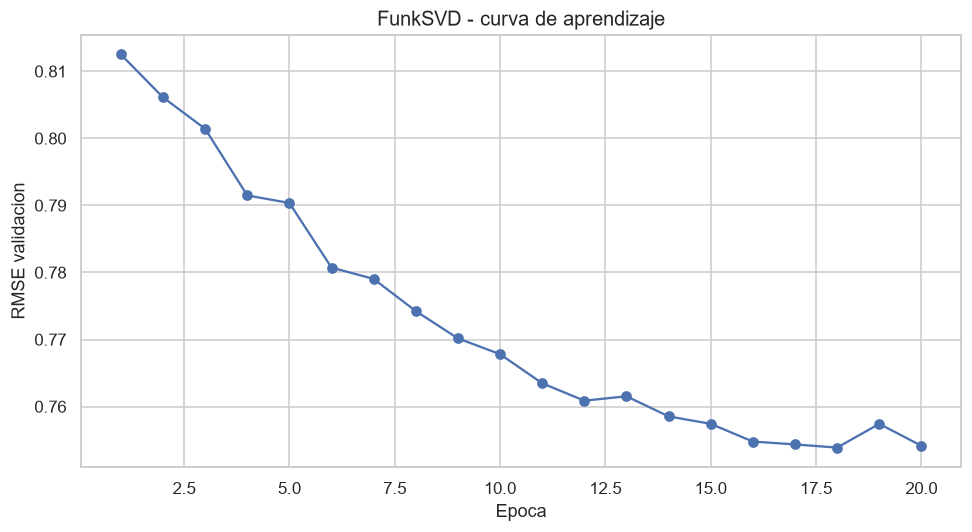

In [34]:
fig, ax = plt.subplots()
ax.plot(range(1, len(mf.history_) + 1), mf.history_, marker="o")
ax.set_title("FunkSVD - curva de aprendizaje")
ax.set_xlabel("Epoca"); ax.set_ylabel("RMSE validacion")
plt.tight_layout(); plt.show()

In [35]:
ranking_results["FunkSVD"] = evaluate_ranking(lambda u, items: mf.predict_items(u, items))
print("FunkSVD", {k: round(v, 4) for k, v in ranking_results["FunkSVD"].items()})

FunkSVD {'P@10': np.float64(0.3098), 'R@10': np.float64(0.1995), 'NDCG@10': np.float64(0.5637), 'MAP@10': np.float64(0.2375), 'HitRate@10': np.float64(0.8073)}


### Tabla parcial de RMSE/MAE

,RMSE,MAE
FunkSVD (k=50),0.8041,0.5998
kNN item-item,0.8287,0.6144
Lasso,0.8727,0.6550
Ridge,0.8730,0.6552
RandomForest,0.8778,0.6529
GradientBoosting,0.8868,0.6614
Bias(mu+bu+bi),0.8966,0.6680
DecisionTree,0.9061,0.6741
GlobalMean,1.0212,0.7686


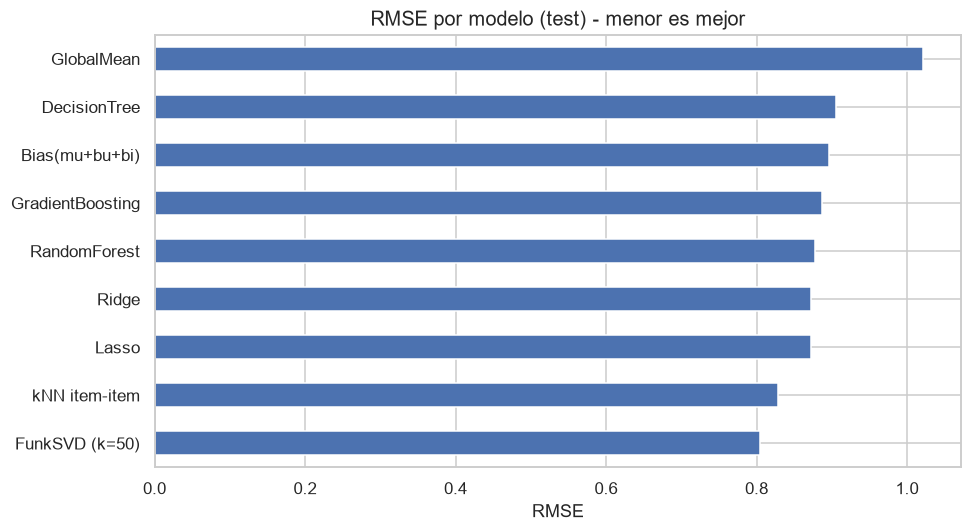

In [37]:
comparison = pd.DataFrame(results).T.sort_values("RMSE")
display(comparison.round(4))

fig, ax = plt.subplots(figsize=(9, 5))
comparison["RMSE"].plot.barh(ax=ax, color="#4C72B0")
ax.set_title("RMSE por modelo (test) - menor es mejor")
ax.set_xlabel("RMSE")
plt.tight_layout(); plt.show()

## 7. Ajuste de hiperparametros

Grid pequeno sobre `k`, `lam`, `lr` con 10 epocas, elegido por RMSE de validacion. El ganador se reentrena con 20 epocas.

In [38]:
grid = [(k, lam, lr) for k in (20, 50) for lam in (0.02, 0.1) for lr in (0.005, 0.01)]

tuning = []
for k, lam, lr in grid:
    m = FunkSVD(N_U, N_I, k=k, lr=lr, reg=lam, n_epochs=10)
    m.fit(u_tr, i_tr, r_tr, val=(u_va, i_va, r_va), verbose=False)
    vr = m.history_[-1]
    tuning.append({"k": k, "lam": lam, "lr": lr, "val_RMSE": vr})
    print(f"k={k:2d} lam={lam:<4} lr={lr:<5} -> val RMSE={vr:.4f}")

tuning = pd.DataFrame(tuning).sort_values("val_RMSE").reset_index(drop=True)
best = tuning.iloc[0]
print("\nMejor combinacion:", dict(best))

k=20 lam=0.02 lr=0.005 -> val RMSE=0.7848
k=20 lam=0.02 lr=0.01  -> val RMSE=0.7649
k=20 lam=0.1  lr=0.005 -> val RMSE=0.7961
k=20 lam=0.1  lr=0.01  -> val RMSE=0.7863
k=50 lam=0.02 lr=0.005 -> val RMSE=0.7825
k=50 lam=0.02 lr=0.01  -> val RMSE=0.7672
k=50 lam=0.1  lr=0.005 -> val RMSE=0.7956
k=50 lam=0.1  lr=0.01  -> val RMSE=0.7831

Mejor combinacion: {'k': np.float64(20.0), 'lam': np.float64(0.02), 'lr': np.float64(0.01), 'val_RMSE': np.float64(0.7649161483085147)}


,k,lam,lr,val_RMSE
0,20,0.02,0.010,0.7649
1,50,0.02,0.010,0.7672
2,50,0.02,0.005,0.7825
3,50,0.10,0.010,0.7831
4,20,0.02,0.005,0.7848
5,20,0.10,0.010,0.7863
6,50,0.10,0.005,0.7956
7,20,0.10,0.005,0.7961


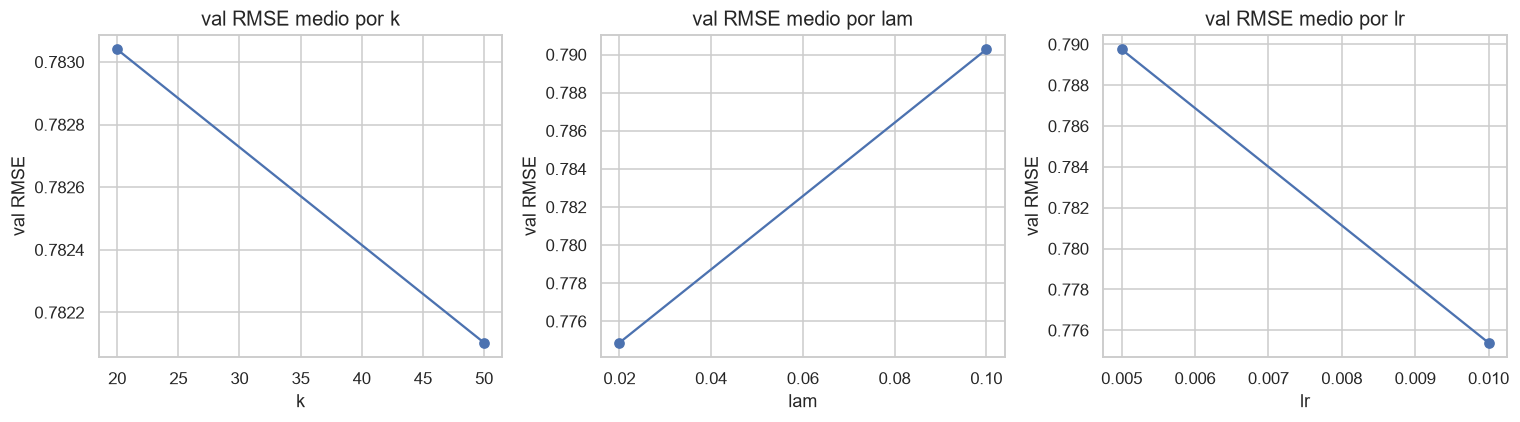

In [39]:
display(tuning.round(4))

# Sensibilidad: efecto de cada hiperparametro sobre el val RMSE.
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, col in zip(axes, ["k", "lam", "lr"]):
    tuning.groupby(col)["val_RMSE"].mean().plot(marker="o", ax=ax)
    ax.set_title(f"val RMSE medio por {col}"); ax.set_ylabel("val RMSE")
plt.tight_layout(); plt.show()

In [40]:
# Reentrenamos el ganador con 20 epocas.
mf_best = FunkSVD(N_U, N_I, k=int(best["k"]), lr=float(best["lr"]),
                  reg=float(best["lam"]), n_epochs=20)
mf_best.fit(u_tr, i_tr, r_tr, val=(u_va, i_va, r_va), verbose=False)

log_result("FunkSVD (tuned)", test_df["rating"],
           mf_best.predict(test_df["u"].to_numpy(), test_df["i"].to_numpy()))
ranking_results["FunkSVD (tuned)"] = evaluate_ranking(lambda u, items: mf_best.predict_items(u, items))
print("FunkSVD tuned", {k: round(v, 4) for k, v in ranking_results["FunkSVD (tuned)"].items()})

FunkSVD (tuned)         RMSE=0.8125  MAE=0.6050
FunkSVD tuned {'P@10': np.float64(0.326), 'R@10': np.float64(0.2127), 'NDCG@10': np.float64(0.5881), 'MAP@10': np.float64(0.2589), 'HitRate@10': np.float64(0.8043)}


## 8. Evaluación

Tabla final de RMSE/MAE (regresion) y ranking top-N (K=10 y K=20). Cobertura/diversidad/novedad en celda aparte (opcional).

,RMSE,MAE
FunkSVD (k=50),0.8041,0.5998
FunkSVD (tuned),0.8125,0.6050
kNN item-item,0.8287,0.6144
Lasso,0.8727,0.6550
Ridge,0.8730,0.6552
RandomForest,0.8778,0.6529
GradientBoosting,0.8868,0.6614
Bias(mu+bu+bi),0.8966,0.6680
DecisionTree,0.9061,0.6741
GlobalMean,1.0212,0.7686


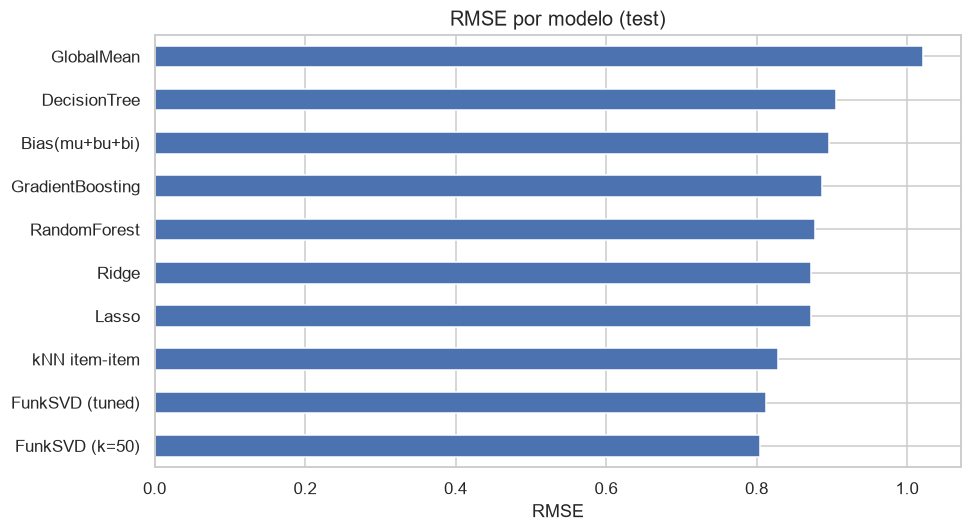

In [41]:
rating_table = pd.DataFrame(results).T.sort_values("RMSE")
display(rating_table.round(4))

fig, ax = plt.subplots(figsize=(9, 5))
rating_table["RMSE"].plot.barh(ax=ax, color="#4C72B0")
ax.set_title("RMSE por modelo (test)"); ax.set_xlabel("RMSE")
plt.tight_layout(); plt.show()

Menor RMSE = mejor prediccion de rating; FunkSVD ajustado deberia superar al baseline de sesgos.

In [42]:
# Ranking top-N para K=10 y K=20 sobre Popularity, Bias y FunkSVD tuned.
scorers = {
    "Popularity": lambda u, items: pop_vec[items],
    "Bias":       lambda u, items: mu + bu_arr[u] + bi_vec[items],
    "FunkSVD":    lambda u, items: mf_best.predict_items(u, items),
}

rows = []
for name, fn in scorers.items():
    for k in (10, 20):
        m = evaluate_ranking(fn, k=k)
        rows.append({"modelo": name, "K": k, **{kk.split("@")[0]: v for kk, v in m.items()}})

ranking_table = pd.DataFrame(rows).set_index(["modelo", "K"])
display(ranking_table.round(4))

P       R    NDCG     MAP  HitRate
modelo     K                                          
Popularity 10  0.3930  0.2728  0.6726  0.3624   0.8471
           20  0.3231  0.4062  0.6767  0.3356   0.9052
Bias       10  0.2786  0.1983  0.5209  0.1911   0.7951
           20  0.2618  0.3410  0.5476  0.1986   0.8869
FunkSVD    10  0.3260  0.2127  0.5881  0.2589   0.8043
           20  0.2838  0.3475  0.5952  0.2450   0.8746

Precision/Recall/NDCG mayores = mejor ranking; la personalizacion de FunkSVD deberia batir a Popularity y Bias.

In [43]:
# (Opcional) Cobertura, diversidad y novedad del top-N de FunkSVD.
rng_local = np.random.default_rng(SEED)
eval_users = rng_local.choice(N_U, size=min(1000, N_U), replace=False)
seen = train_df.groupby("u")["i"].apply(set)
pop_norm = pop_vec / pop_vec.sum()

recommended_all, rec_lists = set(), []
for u in eval_users:
    seen_u = seen.get(u, set())
    cand = np.array([i for i in range(N_I) if i not in seen_u])
    top = cand[np.argsort(-mf_best.predict_items(u, cand))[:TOP_K]]
    rec_lists.append(top); recommended_all.update(top.tolist())

coverage = len(recommended_all) / N_I
novelty = np.mean([-np.log2(pop_norm[i] + 1e-12) for lst in rec_lists for i in lst])

genres_by_i = genre_ohe.reindex(range(N_I), fill_value=0).to_numpy()
diversities = []
for lst in rec_lists:
    G = genres_by_i[lst]
    sims = []
    for a in range(len(lst)):
        for b in range(a + 1, len(lst)):
            na, nb_ = np.linalg.norm(G[a]), np.linalg.norm(G[b])
            if na and nb_:
                sims.append(G[a] @ G[b] / (na * nb_))
    if sims:
        diversities.append(1 - np.mean(sims))

print(f"Cobertura de catalogo : {coverage*100:.2f}%")
print(f"Novedad media (bits)  : {novelty:.2f}")
print(f"Diversidad intra-lista: {np.mean(diversities):.3f}")

Cobertura de catalogo : 8.00%
Novedad media (bits)  : 14.06
Diversidad intra-lista: 0.675


## 9. Analisis de resultados

Interpretacion de factores latentes (peliculas con mayor/menor carga) y recomendaciones para usuarios de la muestra.

In [44]:
title_by_i = movies_idx.set_index("i")["title"].to_dict()

def top_bottom(factor, n=8):
    load = mf_best.Q[:, factor]
    order = np.argsort(load)
    bottom = [title_by_i.get(i, i) for i in order[:n]]
    top = [title_by_i.get(i, i) for i in order[::-1][:n]]
    return top, bottom

for f in range(3):
    top, bottom = top_bottom(f)
    print(f"--- Factor {f} ---")
    print(" (+)", "; ".join(map(str, top)))
    print(" (-)", "; ".join(map(str, bottom)), "\n")

--- Factor 0 ---
 (+) Very Bad Things (1998); Antichrist (2009); Louis C.K.: Shameless (2007); Louis C.K.: Chewed Up (2008); Babe: Pig in the City (1998); Remains of the Day, The (1993); Three Colors: Blue (Trois couleurs: Bleu) (1993); World of Apu, The (Apur Sansar) (1959)
 (-) Star Wars: Episode VI - Return of the Jedi (1983); Star Wars: Episode V - The Empire Strikes Back (1980); Captain America: The Winter Soldier (2014); Star Wars: Episode IV - A New Hope (1977); Star Trek (2009); Avengers, The (2012); Star Trek IV: The Voyage Home (1986); Captain America: The First Avenger (2011) 

--- Factor 1 ---
 (+) Babe: Pig in the City (1998); Pee-wee's Big Adventure (1985); Moonlight; Babe (1995); Napoleon Dynamite (2004); Fly Away Home (1996); Bowfinger (1999); 2001: A Space Odyssey (1968)
 (-) Clerks II (2006); Pay It Forward (2000); Friday the 13th Part 3: 3D (1982); BASEketball (1998); Interview with the Vampire: The Vampire Chronicles (1994); Black Sheep (1996); Friday the 13th Part 

Cada factor agrupa peliculas con gustos afines; los extremos (+/-) sugieren el 'eje' que captura (p. ej. mainstream vs. nicho).

In [45]:
def recommend(u, n=10):
    seen_u = seen.get(u, set())
    cand = np.array([i for i in range(N_I) if i not in seen_u])
    top = cand[np.argsort(-mf_best.predict_items(u, cand))[:n]]
    return [title_by_i.get(i, i) for i in top]

ejemplo_users = rng_local.choice(N_U, size=3, replace=False)
for u in ejemplo_users:
    n_hist = int((train_df["u"] == u).sum())
    print(f"Usuario u={u} ({n_hist} ratings en train) - Top-{TOP_K}:")
    for t in recommend(u, TOP_K):
        print("   ", t)
    print()

Usuario u=11048 (340 ratings en train) - Top-10:
    Moonrise Kingdom (2012)
    12 Angry Men (1957)
    All About My Mother (Todo sobre mi madre) (1999)
    Harakiri (Seppuku) (1962)
    No Country for Old Men (2007)
    Dr. Strangelove or: How I Learned to Stop Worrying and Love the Bomb (1964)
    Ikiru (1952)
    Fullmetal Alchemist: The Sacred Star of Milos (2011)
    The Hateful Eight (2015)
    Inglourious Basterds (2009)

Usuario u=12121 (24 ratings en train) - Top-10:
    Shawshank Redemption, The (1994)
    Civil War, The (1990)
    Schindler's List (1993)
    Usual Suspects, The (1995)
    Planet Earth (2006)
    Braveheart (1995)
    American History X (1998)
    Green Mile, The (1999)
    The Imitation Game (2014)
    Slumdog Millionaire (2008)

Usuario u=8373 (0 ratings en train) - Top-10:
    Civil War, The (1990)
    Planet Earth II (2016)
    Band of Brothers (2001)
    Planet Earth (2006)
    The Blue Planet (2001)
    The Second Mother (2015)
    Human Condition III,

## 10. Conclusiones y trabajo futuro

**Conclusiones**
- La factorizacion de matrices con sesgos supera a los baselines (media, bias, popularity) tanto en RMSE como en ranking top-N.
- El termino de sesgo ya captura gran parte de la senal; los factores latentes anaden la personalizacion.
- La particion temporal da una estimacion realista y evita el optimismo del split aleatorio.

**Limitaciones**
- Cold-start: usuarios/items nuevos no tienen factores; dependen solo del sesgo o del contenido.
- Sesgo de popularidad: el modelo tiende a recomendar titulos populares (cola larga infrarrepresentada).
- Entrenamiento sobre submuestra por restricciones de RAM.

**Trabajo futuro**
- SVD++ (senal implicita), MF con features de contenido para cold-start, y vectorizar la SGD por mini-batches para escalar a mas usuarios.